# Brand Sentiment Analysis (YouTube Comments)
**Kaise chalana hai:** upar menu se *Runtime > Run all* karo, ya har cell ko upar se neeche ek ek karke run karo (▶ button).
Sirf **Cell 2** me apna brand aur API key daalni hai.

## Cell 1: Libraries install

In [ ]:
!pip install -q google-api-python-client vaderSentiment wordcloud

## Cell 2: Settings (yahan brand aur API key daalo)

In [ ]:
from getpass import getpass

BRAND = "Khaadi"          # <- apne clothing brand ka naam
NUM_VIDEOS = 10           # kitni videos se comments lene hain
COMMENTS_PER_VIDEO = 300  # har video se max comments
MODEL = "vader"           # "vader" (fast) ya "xlmr" (multilingual, slow)

API_KEY = getpass("YouTube API key paste karo:")

YouTube API key paste karo:··········


## Cell 3: Comments scrape karo

In [ ]:
import time
import pandas as pd
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

yt = build("youtube", "v3", developerKey=API_KEY)

def search_videos(query, n):
    out, token = [], None
    while len(out) < n:
        res = yt.search().list(q=query, part="id,snippet", type="video",
                               maxResults=min(50, n - len(out)),
                               pageToken=token, order="relevance").execute()
        out += [(i["id"]["videoId"], i["snippet"]["title"]) for i in res["items"]]
        token = res.get("nextPageToken")
        if not token:
            break
    return out[:n]

def get_comments(video_id, title, max_comments):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            res = yt.commentThreads().list(part="snippet", videoId=video_id,
                                           maxResults=100, pageToken=token,
                                           textFormat="plainText",
                                           order="relevance").execute()
        except HttpError as e:
            print("  skip (comments band ya error):", title[:40])
            break
        for it in res["items"]:
            s = it["snippet"]["topLevelComment"]["snippet"]
            rows.append({"video_title": title, "comment": s["textDisplay"],
                         "likes": s["likeCount"], "published_at": s["publishedAt"]})
        token = res.get("nextPageToken")
        if not token:
            break
        time.sleep(0.2)
    return rows[:max_comments]

videos = search_videos(f"{BRAND} review", NUM_VIDEOS)
print(len(videos), "videos mile")
rows = []
for vid, title in videos:
    print("Scraping:", title[:60])
    rows += get_comments(vid, title, COMMENTS_PER_VIDEO)

df = pd.DataFrame(rows).drop_duplicates(subset="comment").reset_index(drop=True)
print("\nTotal comments:", len(df))
df.head()

10 videos mile
Scraping: Khaadi Winter Collection 2026 ✨️ | Prices &amp; Flat 50% OFF
Scraping: How Khaadi kurta looks on model Vs Me | Online vs Reality | 
Scraping: Khaadi Perfume &amp; Body Mist Collection Review 💕 Hype vs R
Scraping: Khaadi Clothing Review 🇵🇰 | Is Khaadi Really Worth It? | Pak
Scraping: Unboxing of khaadi || honest review
Scraping: the real-est try-on haul *unfiltered* ft. Khaadi
Scraping: Khaadi Shalwar Review: Is It Worth the Hype? #fashion #noore
Scraping: khaadi SUPER FLAT 70%OFF GRAND SALE 😱🔥😍 khaadi sale 2026❤️📣 
Scraping: Khaadi  || Khaadi Sale Flat 40 % OFF Unstitched &amp; Stitch
Scraping: Khaadi Sale Today 2025 #khaadi #sale #summercollection #tren

Total comments: 162


,video_title,comment,likes,published_at
0,Khaadi Winter Collection 2026 ✨️ | Prices &amp...,Walaikum assalam,0,2026-10-29T09:53:57Z
1,How Khaadi kurta looks on model Vs Me | Online...,It's interesting how different it looks. Those...,1,2023-09-14T00:30:37Z
2,How Khaadi kurta looks on model Vs Me | Online...,What size r wearing? In khaadi?,0,2026-04-20T04:44:44Z
3,Unboxing of khaadi || honest review,🎉,0,2023-09-11T10:27:21Z
4,Unboxing of khaadi || honest review,😢,0,2023-10-07T16:05:41Z


## Cell 4: Sentiment analysis

In [ ]:
import re

def clean(t):
    t = re.sub(r"http\S+|www\.\S+", " ", str(t))
    t = re.sub(r"@\w+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["comment"].map(clean)
df = df[df["clean"].str.len() > 2].reset_index(drop=True)

if MODEL == "vader":
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    scores = [sia.polarity_scores(t)["compound"] for t in df["clean"]]
    df["score"] = scores
    df["sentiment"] = ["Positive" if s >= 0.05 else "Negative" if s <= -0.05 else "Neutral"
                       for s in scores]
else:
    !pip install -q transformers torch
    from transformers import pipeline
    clf = pipeline("sentiment-analysis",
                   model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                   truncation=True, max_length=128)
    res = clf(df["clean"].tolist(), batch_size=32)
    df["sentiment"] = [r["label"].capitalize() for r in res]
    df["score"] = [r["score"] for r in res]

counts = df["sentiment"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

sentiment
Positive    98
Neutral     52
Negative     8
Name: count, dtype: int64
sentiment
Positive    62.0 %
Neutral     32.9 %
Negative     5.1 %
Name: count, dtype: object


## Cell 5: Charts

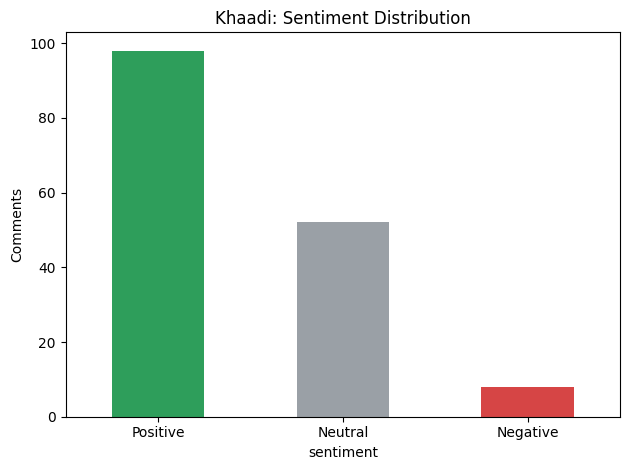

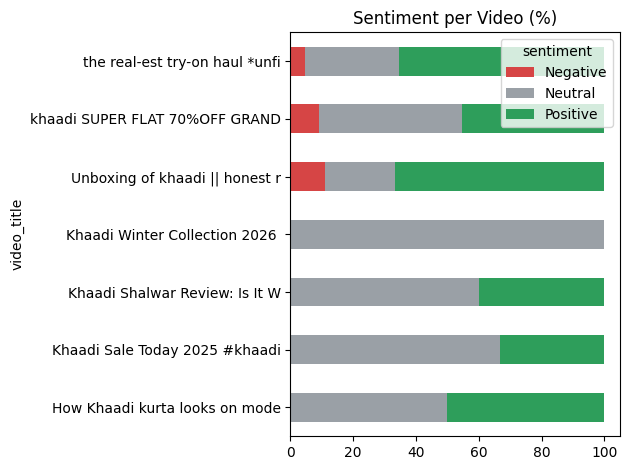

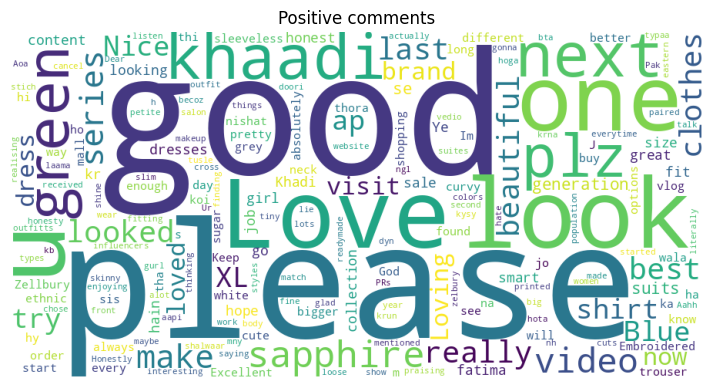

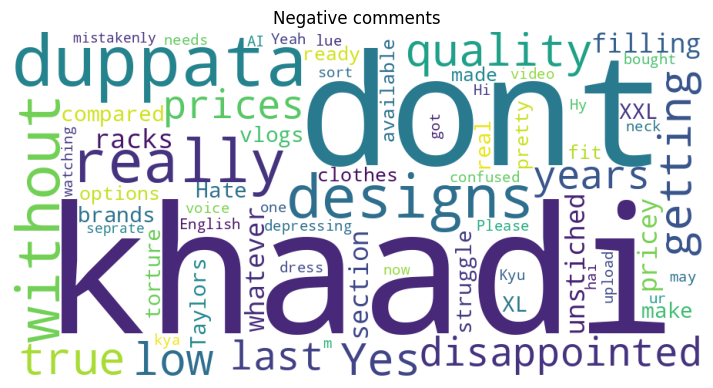

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

colors = {"Positive": "#2e9e5b", "Neutral": "#9aa0a6", "Negative": "#d64545"}

# 1) Overall distribution
counts.plot(kind="bar", color=[colors.get(k, "#555") for k in counts.index])
plt.title(f"{BRAND}: Sentiment Distribution"); plt.ylabel("Comments")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("distribution.png", dpi=150); plt.show()

# 2) Per video
pv = pd.crosstab(df["video_title"].str[:30], df["sentiment"], normalize="index") * 100
pv.plot(kind="barh", stacked=True, color=[colors.get(c, "#555") for c in pv.columns])
plt.title("Sentiment per Video (%)"); plt.tight_layout()
plt.savefig("per_video.png", dpi=150); plt.show()

# 3) Word clouds
for label in ["Positive", "Negative"]:
    text = " ".join(df.loc[df["sentiment"] == label, "clean"])
    if len(text) > 20:
        wc = WordCloud(width=900, height=450, background_color="white").generate(text)
        plt.figure(figsize=(9, 4.5)); plt.imshow(wc); plt.axis("off")
        plt.title(f"{label} comments"); plt.savefig(f"wordcloud_{label.lower()}.png", dpi=150)
        plt.show()

## Cell 6: Sample comments dekho (accuracy check)

In [ ]:
for label in ["Positive", "Negative", "Neutral"]:
    print(f"\n=== {label} ===")
    for t in df[df["sentiment"] == label]["clean"].head(5):
        print("-", t[:150])


=== Positive ===
- It's interesting how different it looks. Those colors really match you!
- Good one 😮
- Plz make vedio for makeup website
- good job, 👍
- ❤❤❤❤❤

=== Negative ===
- Yes quality of khaadi getting low 😢
- So true... Khaadi really disappointed me with their designs for the prices .. last 2 /3 years they are just filling racks with whatever.. also unstich
- The struggle for XL / XXL is real Do make more of these vlogs. Hate the Taylors torture but no options available in ready made
- Khaadi has pretty clothes but they dont fit me and its depressing 😢😢😢
- English may Kyu Hy 😢

=== Neutral ===
- Walaikum assalam
- What size r wearing? In khaadi?
- Ma'am online order kren to Khaadi ka handbag wala envelope ata hai? Ya sirf lamination packing ati hai?
- Sorry but I think it's a design .dark and light shade..
- Fatima long length shirts suits you so much


## Cell 7: Results download karo

In [ ]:
import glob, zipfile
from google.colab import files

df.to_csv("results.csv", index=False, encoding="utf-8-sig")
with zipfile.ZipFile("results.zip", "w") as z:
    for f in ["results.csv"] + glob.glob("*.png"):
        z.write(f)
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>